# Effects

A retro game title screen: the title's two words carry their own effects, "Press start" blinks, and the menu
buttons glow and respond to the pointer. Each effect styles a range of the text or a whole shape, so the
title stays real, selectable text, and every effect animates with SMIL: the SVG plays in a browser and the GIF
plays anywhere.

In [1]:
import functools

from IPython import display as ipy
import svgwriter as svg

from animations import twinkle
from components import card

The project's theme applies to every drawing below, as it does when the project builds.

In [2]:
project = svg.Project.load()
theme = svg.Theme.load(project.config.theme)

In [3]:
EFFECT_NAMES = list(svg.effects.__all__)
INSET = 16              # card edge to page edge
TITLE = (480, 210)      # centre and baseline of the title
SUBTITLE_Y = 262        # baseline of the tagline
START_Y = 340           # baseline of "Press start"
MENU = ("New game", "Continue", "Options")
MENU_TOP = 380          # top of the first menu button
BUTTON = (220, 36, 12)  # width, height and gap of the menu buttons
LABEL_INK = "#0f172a"   # button labels, dark on the lit buttons

`title[start:end].effect(name)` moves that range of the title onto a copy just above it, so each word gets
its own effect while the line keeps its spacing. Dropdowns pick the effects, so `svgwriter preview` (or
`svg.explore` in a notebook) can try them all.

In [4]:
def effect_choice(label: str, value: str) -> svg.widgets.Dropdown:
    """The dropdown that picks the effect of *label*, starting at *value*."""
    return svg.widgets.Dropdown(EFFECT_NAMES, value=value, label=label)


def menu(doc: svg.Document, effect: str) -> None:
    """The menu: one lit button per entry, each dimming on hover and flashing when pressed."""
    width, height, gap = BUTTON
    for index, label in enumerate(MENU):
        top = MENU_TOP + index * (height + gap)
        button = doc.group()
        button.rect(TITLE[0] - width / 2, top, width, height, rx=height / 2, stroke_width=2).effect(effect)
        button.text(label, x=TITLE[0], y=top + height / 2 + 6, font_size=18, text_anchor="middle", fill=LABEL_INK)
        button.interact.button()


@svg.widgets.controls(title=svg.widgets.Text("Star Drift"), first=effect_choice("first word", "fire"),
                      second=effect_choice("second word", "metal"), buttons=effect_choice("buttons", "neon"))
def title_screen(doc: svg.Document, *, title: str = "Star Drift", first: str = "fire", second: str = "metal",
                 buttons: str = "neon") -> svg.Document:
    """Draw the starry card, the title with an effect on each word, the blinking prompt and the menu."""
    box = doc.root.get("viewBox")
    sky = card(box.width, box.height, inset=INSET, caption="svg.effects")
    doc += sky
    sky.children[2].animate.apply(twinkle)
    words = title.split(" ", 1)
    line = doc.text(title, x=TITLE[0], y=TITLE[1], font_size=96, font_weight="bold", text_anchor="middle",
                    letter_spacing=4).as_role("text")
    line[0:len(words[0])].effect(first)
    if len(words) > 1:
        line[len(words[0]) + 1:len(title)].effect(second)
    doc.text("A journey past the last lighthouse", x=TITLE[0], y=SUBTITLE_Y, text_anchor="middle",
             font_size=20).as_role("caption")
    prompt = doc.text("PRESS START", x=TITLE[0], y=START_Y, text_anchor="middle", font_size=22,
                      letter_spacing=6, font_weight="bold", fill="#fde68a")
    prompt.animate.apply(twinkle, low=0.0, dur=1.2)
    menu(doc, buttons)
    doc.text("v1.0", x=INSET + 24, y=box.height - INSET - 16).as_role("caption")
    return doc

Every control of `title_screen` becomes an input: in a running notebook (with the `widget` extra) this panel redraws the drawing as you change them. A saved notebook cannot keep live widgets, so the stills below show other values.

In [5]:
def in_project(function):
    @functools.wraps(function)
    def draw(doc, **values):
        size = project.config.size
        sheet = svg.Document(*size, theme=theme) if isinstance(size, tuple) else svg.Document(size=size, theme=theme)
        with theme:
            result = function(sheet, **values)
        return sheet if result is None else result

    return draw


def show(function, **values):
    ipy.display(ipy.SVG(data=in_project(function)(None, **values).to_string()))


svg.explore(in_project(title_screen))

The same function for other control values.

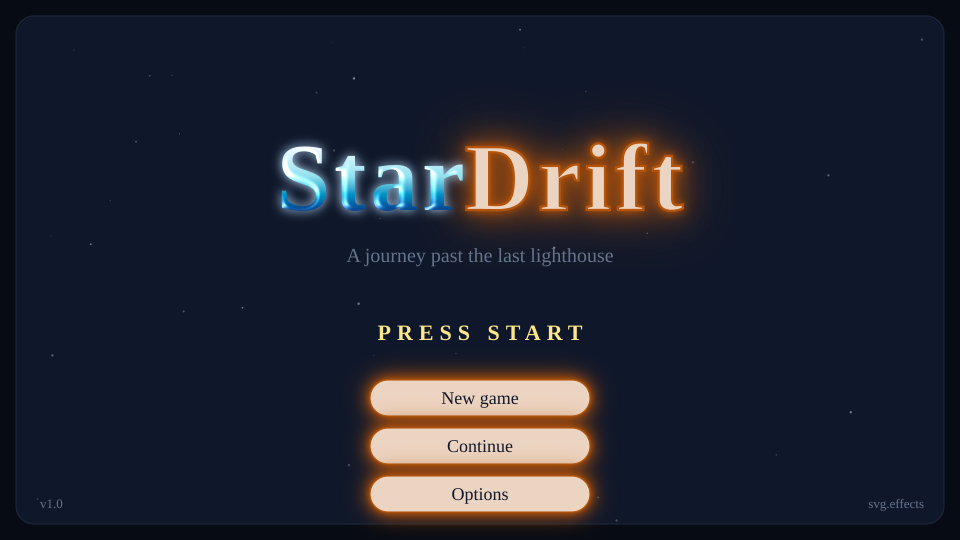

In [6]:
show(title_screen, **{'first': 'ice', 'second': 'neon'})

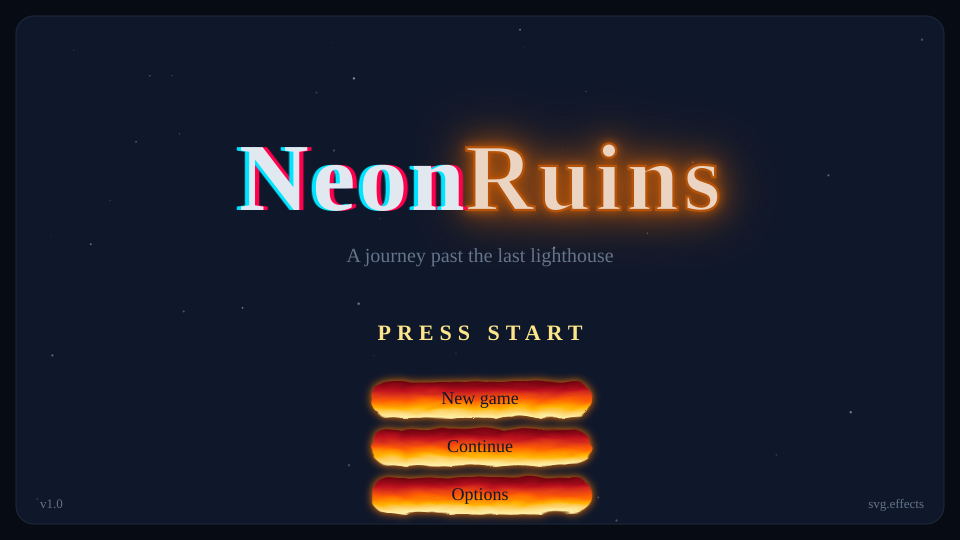

In [7]:
show(title_screen, **{'title': 'Neon Ruins', 'first': 'glitch', 'second': 'neon', 'buttons': 'fire'})

`project.build` writes the outputs listed in `svgwriter.toml` (here only the SVG, which keeps animations as SMIL) and the notebook shows each one.

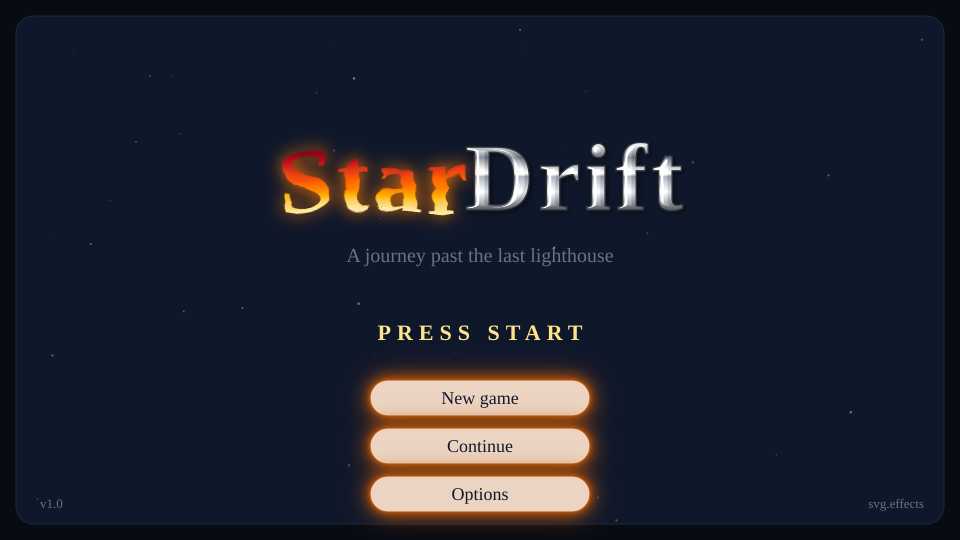

In [8]:
for path in project.build(["svg"]):
    ipy.display(ipy.SVG(filename=str(path)))